# Project: Marketing Campaigns
### Problem Scenario: ‘Marketing mix’ is a popular concept used in implementing marketing strategies. A marketing mix includes multiple areas of focus as part of a comprehensive marketing plan. This all revolves around the four Ps of marketing - product, price, place, and promotion.
    
### Problem Objective: As a data scientist, you should perform exploratory data analysis and hypothesis testing. The goal is to gain a better understanding of the various factors that contribute to customer acquisition.
    
## Data Description:
### The variables birth-year, education, income, and so on are related to the first 'P' or 'People' in	 user. The amount spent on wine, fruits, gold, etc., is related to ‘Product’. The information pertinent to sales channels, like websites, stores, etc., is related to ‘Place’, and the fields which talk about promotions and results of different campaigns are related to ‘Promotion’.

## Steps to Perform:

### Once data is imported, investigate variables like Dt_Customer and Income, etc., and check if they are imported correctly.

###  Income values for a few customers are missing. Perform missing value imputation. Assume that the customers with similar education and marital status make the same yearly income, on average. You may have to clean the data before performing this. For data cleaning, look into the categories of education and marital status. 

### Create variables to populate the total number of children, age, and total spending. 

### Hint: From the number of purchases through the three channels, people can derive the total purchases.

### Create box plots and histograms to understand the distributions and outliers. Perform outlier treatment.

### Use ordinal encoding and one hot encoding according to different types of categorical variables.

### Create a heatmap to showcase the correlation between different pairs of variables.

### Test the following hypotheses:

### Older people are not as tech-savvy and probably prefer shopping in-store.
### Customers with kids probably have less time to visit a store and would prefer to shop online.
### Other distribution channels may cannibalize sales at the store.
### Does the US fare significantly better than the rest of the world in terms of total purchases?


### Use appropriate visualization to help analyze the following:

### Which products are performing the best, and which are performing the least in terms of revenue?
### Is there any pattern between the age of customers and the last campaign acceptance rate?
### Which Country has the greatest number of customers who accepted the last campaign?
### Do you see any pattern in the no. of children at home and total spend?
### Education background of the customers who complained in the last 2 years.


In [433]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [434]:
metadata = pd.read_excel("1688639964_datadictionaryresponsetomarketingcampaigns.xlsx")

# Understanding the data

In [228]:
metadata

,Variable,Description
0,ID,Customer's unique identifier
1,Year_Birth,Customer's birth year
2,Education,Customer's education level
3,Marital_Status,Customer's marital status
4,Income,Customer's yearly household income
5,Kidhome,number of small children in customer's househo...
6,Teenhome,no of teenagers in customer's house
7,Dt_Customer,Date of customer's enrollment with the company
8,Recency,number of days since the last purchase
9,MntWines,amount spent on wine in last 2 years


In [436]:
df = pd.read_csv("marketing_data.csv")

In [437]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
0,1826,1970,Graduation,Divorced,"$84,835.00",0,0,6/16/14,0,189,...,6,1,0,0,0,0,0,1,0,SP
1,1,1961,Graduation,Single,"$57,091.00",0,0,6/15/14,0,464,...,7,5,0,0,0,0,1,1,0,CA
2,10476,1958,Graduation,Married,"$67,267.00",0,1,5/13/14,0,134,...,5,2,0,0,0,0,0,0,0,US
3,1386,1967,Graduation,Together,"$32,474.00",1,1,5/11/14,0,10,...,2,7,0,0,0,0,0,0,0,AUS
4,5371,1989,Graduation,Single,"$21,474.00",1,0,4/8/14,0,6,...,2,7,1,0,0,0,0,1,0,SP


In [438]:
df.tail()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
2235,10142,1976,PhD,Divorced,"$66,476.00",0,1,3/7/13,99,372,...,11,4,0,0,0,0,0,0,0,US
2236,5263,1977,2n Cycle,Married,"$31,056.00",1,0,1/22/13,99,5,...,3,8,0,0,0,0,0,0,0,SP
2237,22,1976,Graduation,Divorced,"$46,310.00",1,0,12/3/12,99,185,...,5,8,0,0,0,0,0,0,0,SP
2238,528,1978,Graduation,Married,"$65,819.00",0,0,11/29/12,99,267,...,10,3,0,0,0,0,0,0,0,IND
2239,4070,1969,PhD,Married,"$94,871.00",0,2,9/1/12,99,169,...,4,7,0,1,1,0,0,1,0,CA


In [439]:
df.describe()

,ID,Year_Birth,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain
count,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000
mean,5592.159821,1968.805804,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,27.062946,...,2.662054,5.790179,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.149107,0.009375
std,3246.662198,11.984069,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,41.280498,...,2.923101,3.250958,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.356274,0.096391
min,0.000000,1893.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2828.250000,1959.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,1.000000,...,0.000000,3.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,5458.500000,1970.000000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,8.000000,...,2.000000,5.000000,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,8427.750000,1977.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,33.000000,...,4.000000,8.000000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,11191.000000,1996.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,263.000000,...,28.000000,13.000000,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [325]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   ID                   2240 non-null   int64
 1   Year_Birth           2240 non-null   int64
 2   Education            2240 non-null   str  
 3   Marital_Status       2240 non-null   str  
 4    Income              2216 non-null   str  
 5   Kidhome              2240 non-null   int64
 6   Teenhome             2240 non-null   int64
 7   Dt_Customer          2240 non-null   str  
 8   Recency              2240 non-null   int64
 9   MntWines             2240 non-null   int64
 10  MntFruits            2240 non-null   int64
 11  MntMeatProducts      2240 non-null   int64
 12  MntFishProducts      2240 non-null   int64
 13  MntSweetProducts     2240 non-null   int64
 14  MntGoldProds         2240 non-null   int64
 15  NumDealsPurchases    2240 non-null   int64
 16  NumWebPurchases      2240 non-null 

In [440]:
# finding out unique categorical data
columns = ['Education', 'Marital_Status', 'Country']
for col in columns:
    print(df[col].unique())


<StringArray>
['Graduation', 'PhD', '2n Cycle', 'Master', 'Basic']
Length: 5, dtype: str
<StringArray>
['Divorced', 'Single', 'Married', 'Together', 'Widow', 'YOLO', 'Alone',
 'Absurd']
Length: 8, dtype: str
<StringArray>
['SP', 'CA', 'US', 'AUS', 'GER', 'IND', 'SA', 'ME']
Length: 8, dtype: str


# EDA

## Columns & Types

### Numerical 
#### -['ID', 'Year_Birth', 'Income', 'Kidhome', 'Teenhome', Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Response', 'Complain']

### categorical 
#### - ['Education', 'Marital_Status', 'Country']

### Mixed 
#### - ['Dt_Customer', 'Country']

#### Removing the extra spaces from each label's

In [441]:
df.columns = df.columns.str.strip()

In [442]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Response', 'Complain', 'Country'],
      dtype='str')

## Income
### Conclusion
#### 1. We can see that Income has a string type, we have converted it to a float type
#### 2. The income field has some missing values too, which we have replaced with the average Income based on the Education and Marital Status
#### 3. There are outliers present in the Income column, we have removed one outlier present that causing the highly positive skew data previous skew value - 6.798008524548168 and after outlier removed we have skewed value near to zero - 0.34848313660926533

In [443]:
df.Income = df.Income.str.replace("$", "")
df.Income = df.Income.str.replace(",", "").astype("float")

In [444]:
df.Income.dtype

dtype('float64')

In [445]:
df.Income

0       84835.0
1       57091.0
2       67267.0
3       32474.0
4       21474.0
         ...   
2235    66476.0
2236    31056.0
2237    46310.0
2238    65819.0
2239    94871.0
Name: Income, Length: 2240, dtype: float64

#### Replacing the 24 missing values present in the Income column with the average based on the Education and Marital Status

In [446]:

df["Income"] = df["Income"].fillna(df.groupby(["Education", "Marital_Status"])["Income"].transform("mean"))

In [447]:
df.Income.isnull().sum()

np.int64(0)

In [448]:
df.Income.describe()

count      2240.000000
mean      52248.748825
std       25039.981052
min        1730.000000
25%       35538.750000
50%       51381.500000
75%       68289.750000
max      666666.000000
Name: Income, dtype: float64

#### By looking into the income information it looks that there is a outlier present in Income column

<Axes: ylabel='Density'>

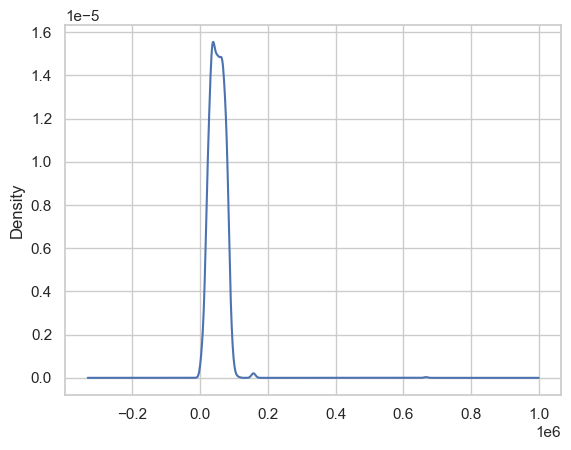

In [449]:
df.Income.plot(kind="kde")

<Axes: >

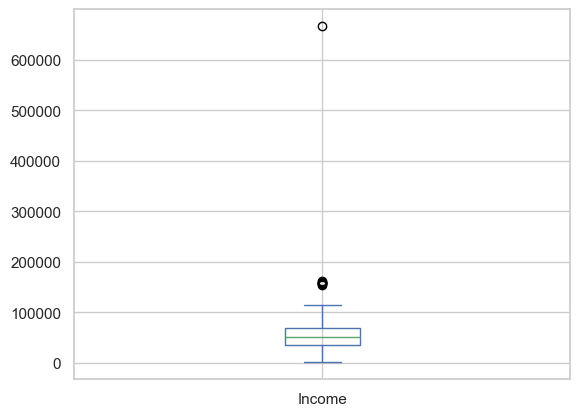

In [450]:
df.Income.plot(kind="box")

In [451]:
df[df.Income> 150000]

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
325,4931,1977,Graduation,Together,157146.0,0,0,4/29/13,13,1,...,0,1,0,0,0,0,0,0,0,SA
497,1501,1982,PhD,Married,160803.0,0,0,8/4/12,21,55,...,1,0,0,0,0,0,0,0,0,US
527,9432,1977,Graduation,Together,666666.0,1,0,6/2/13,23,9,...,3,6,0,0,0,0,0,0,0,SA
731,1503,1976,PhD,Together,162397.0,1,1,6/3/13,31,85,...,1,1,0,0,0,0,0,0,0,SP
853,5336,1971,Master,Together,157733.0,1,0,6/4/13,37,39,...,1,1,0,0,0,0,0,0,0,SP
1826,5555,1975,Graduation,Divorced,153924.0,0,0,2/7/14,81,1,...,0,0,0,0,0,0,0,0,0,SP
1925,11181,1949,PhD,Married,156924.0,0,0,8/29/13,85,2,...,0,0,0,0,0,0,0,0,0,CA
2204,8475,1973,PhD,Married,157243.0,0,1,3/1/14,98,20,...,0,0,0,0,0,0,0,0,0,IND


In [452]:
df.Income.skew()

np.float64(6.798008524548168)

In [453]:
df.drop(index=527, inplace=True)

In [454]:
df[df.Income> 150000]

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
325,4931,1977,Graduation,Together,157146.0,0,0,4/29/13,13,1,...,0,1,0,0,0,0,0,0,0,SA
497,1501,1982,PhD,Married,160803.0,0,0,8/4/12,21,55,...,1,0,0,0,0,0,0,0,0,US
731,1503,1976,PhD,Together,162397.0,1,1,6/3/13,31,85,...,1,1,0,0,0,0,0,0,0,SP
853,5336,1971,Master,Together,157733.0,1,0,6/4/13,37,39,...,1,1,0,0,0,0,0,0,0,SP
1826,5555,1975,Graduation,Divorced,153924.0,0,0,2/7/14,81,1,...,0,0,0,0,0,0,0,0,0,SP
1925,11181,1949,PhD,Married,156924.0,0,0,8/29/13,85,2,...,0,0,0,0,0,0,0,0,0,CA
2204,8475,1973,PhD,Married,157243.0,0,1,3/1/14,98,20,...,0,0,0,0,0,0,0,0,0,IND


In [455]:
df.Income.skew()

np.float64(0.34848313660926533)

<Axes: >

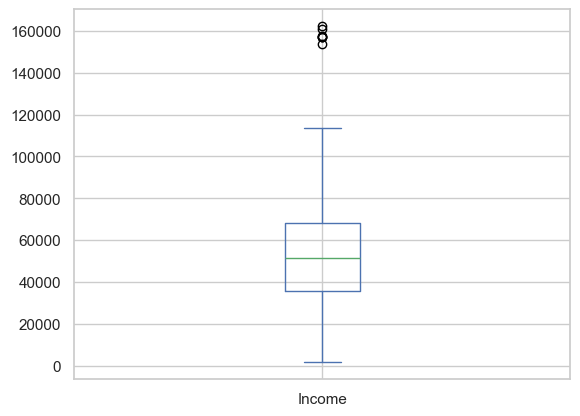

In [456]:
df.Income.plot(kind="box")

In [457]:
df.Income.describe()

count      2239.000000
mean      51974.332902
std       21413.179581
min        1730.000000
25%       35533.500000
50%       51373.000000
75%       68277.500000
max      162397.000000
Name: Income, dtype: float64

<Axes: ylabel='Density'>

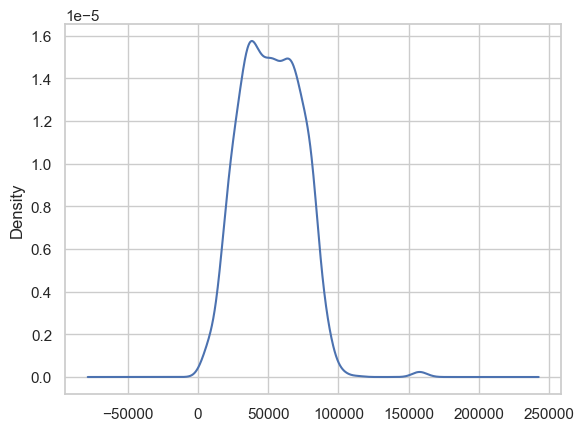

In [458]:
df.Income.plot(kind="kde")

### Scaled down the Income field by dividing with maximum income

In [459]:
df["Income"].max()
df["Scaled_Income"] = df["Income"]/df["Income"].max()

<Axes: ylabel='Density'>

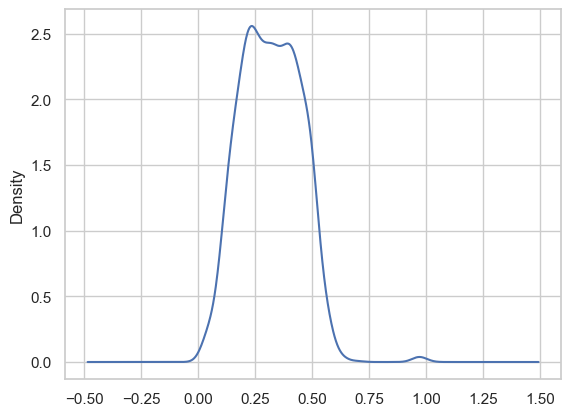

In [460]:
df["Scaled_Income"].plot(kind="kde")

## Age
### Conclusion
#### 1. By looking into data, we can see that the year of birth is given in age columns, so we had computed the age of the customer by subtracting the year_birth from current year and added it under a new column Customer_Age
#### 2. By box plot chart we can see there are outlier present in age column, we had removed those outlier.

In [461]:
# adding new column Customer_Age in integer type
df["Customer_Age"]  = 2026 - df.Year_Birth

<Axes: >

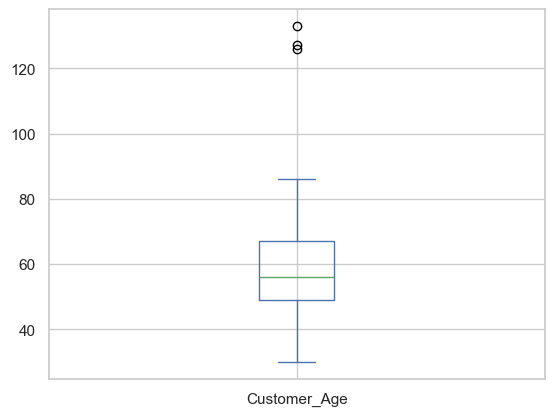

In [462]:
df["Customer_Age"].plot(kind="box")

In [463]:
df[df["Customer_Age"]>95]

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country,Scaled_Income,Customer_Age
513,11004,1893,2n Cycle,Single,60182.0,0,1,5/17/14,23,8,...,0,0,0,0,0,0,0,SA,0.370586,133
827,1150,1899,PhD,Together,83532.0,0,0,9/26/13,36,755,...,0,0,1,0,0,0,0,SP,0.514369,127
2233,7829,1900,2n Cycle,Divorced,36640.0,1,0,9/26/13,99,15,...,0,0,0,0,0,0,1,IND,0.225620,126


In [464]:
df["Customer_Age"].describe()

count    2239.000000
mean       57.197856
std        11.985494
min        30.000000
25%        49.000000
50%        56.000000
75%        67.000000
max       133.000000
Name: Customer_Age, dtype: float64

In [467]:
df.drop(index=513, inplace=True)
df.drop(index=827, inplace=True)
df.drop(index=2233, inplace=True)

<Axes: >

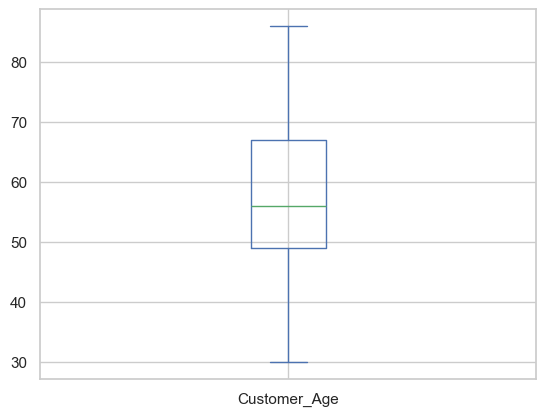

In [468]:
df["Customer_Age"].plot(kind="box")

In [469]:
df["Customer_Age"].describe()

count    2236.000000
mean       57.101968
std        11.703281
min        30.000000
25%        49.000000
50%        56.000000
75%        67.000000
max        86.000000
Name: Customer_Age, dtype: float64

In [470]:
df["Customer_Age"].isnull().sum()

np.int64(0)

## Children - Kidhome & TeenHome
### Conclusion

#### 1. We have found the total number of children a customer has by adding the Kidhome and Teenhome data, and added a new column, Total_Children
#### 2. Outliers are present. Also, we found that 53 customers have a total number of children 3, and we are not removing because skewness if near to zero 0.415519291057909.
#### 3. 0 and 3 are the min and max children count

In [471]:
# Finding out the total number of children a customer has added under the new column Total_Children
df["Total_Children"] = df.Kidhome + df.Teenhome
df["Total_Children"].skew()

np.float64(0.415519291057909)

np.int64(53)

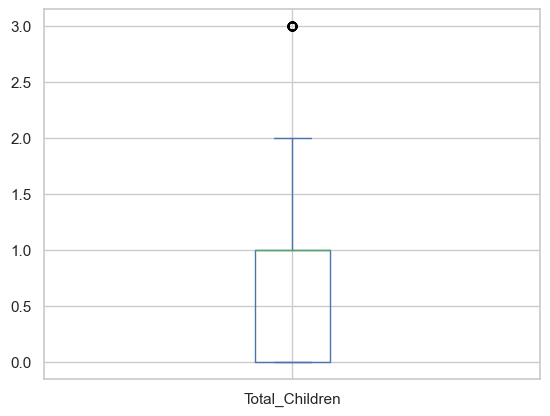

In [473]:
df["Total_Children"].plot(kind="box")
df["Total_Children"][df["Total_Children"]==3].count()

## Products - MntFishProducts, MntFruits, MntGoldProds, MntMeatProducts, MntSweetProducts, MntWines

## conclusion
#### 1. total spending of the customer by adding the prices of each product
#### 2. skewness is also near zero, 0.8601739694705927, so we are not removing any outliers
#### 3. Wine is the most hightest bought product by most of the customers. Meat products are the second most bought.
#### 4. People are more into buying wine as they age.

In [474]:
# Finding out the total spending a customer has, and adding it under the new column Total_Spending
df["Total_Spending"] = (df.MntFishProducts + df.MntFruits 
                        + df.MntGoldProds + df.MntMeatProducts 
                        + df.MntSweetProducts + df.MntWines)

In [475]:
df["Total_Spending"].describe()

count    2236.000000
mean      605.986583
std       601.865156
min         5.000000
25%        69.000000
50%       396.500000
75%      1045.500000
max      2525.000000
Name: Total_Spending, dtype: float64

np.float64(0.8601739694705927)

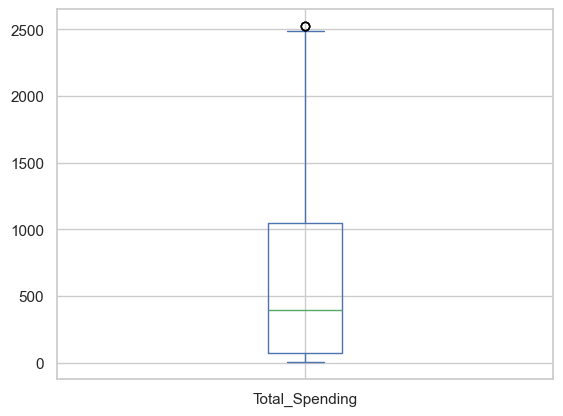

In [476]:
df["Total_Spending"].plot(kind="box")
df["Total_Spending"].skew()

In [365]:
product_cols = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
product_spend = df[product_cols].sum()

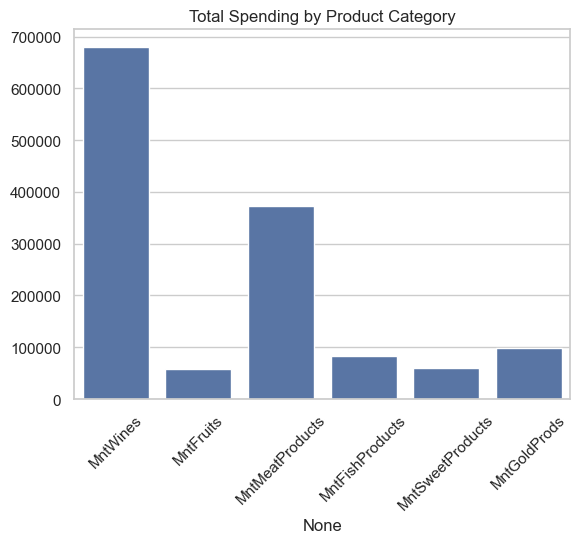

In [477]:
sns.barplot(x=product_spend.index, y=product_spend.values)
plt.title("Total Spending by Product Category")
plt.xticks(rotation=45)
plt.show()

In [479]:
# creating age range to get the most purchases in what age range
bins = [0, 30, 45, 60, 120] 
labels = ["0-30", "30-45", "45-60", ">60"]
df["Age_Range"] = pd.cut(df["Customer_Age"], bins=bins, labels=labels, right=False)

product_cols = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
age_product_spend = df.groupby("Age_Range")[product_cols].sum()
age_product_spend = age_product_spend.reset_index().melt(id_vars="Age_Range", 
                                                         var_name="Product", 
                                                         value_name="Spend")
age_product_spend

,Age_Range,Product,Spend
0,30-45,MntWines,88348
1,45-60,MntWines,259090
2,>60,MntWines,332591
3,30-45,MntFruits,10107
4,45-60,MntFruits,23440
5,>60,MntFruits,25206
6,30-45,MntMeatProducts,67020
7,45-60,MntMeatProducts,142510
8,>60,MntMeatProducts,163845
9,30-45,MntFishProducts,13665


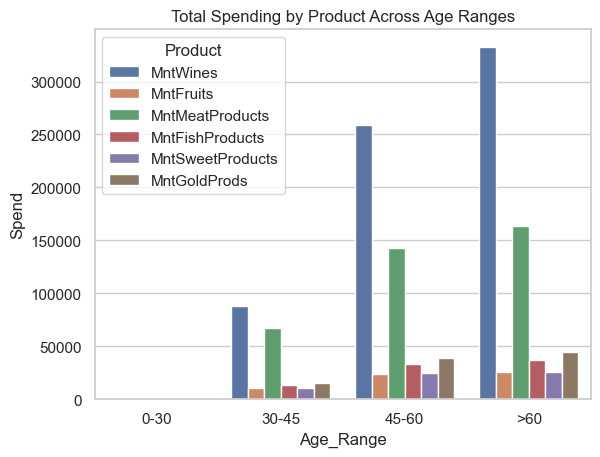

In [480]:
sns.barplot(data=age_product_spend, x="Age_Range", y="Spend", hue="Product")
plt.title("Total Spending by Product Across Age Ranges")
plt.show()

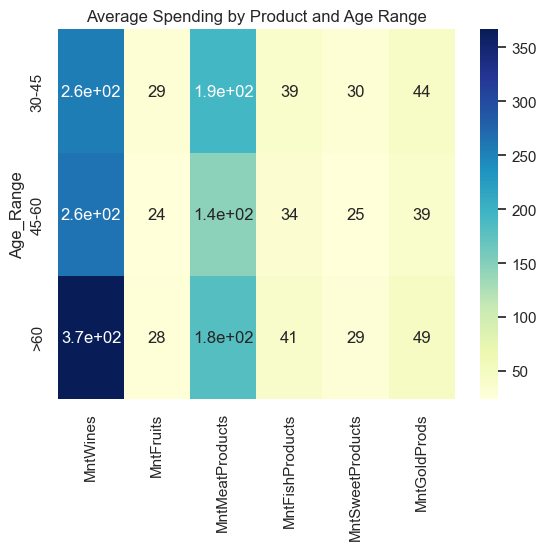

In [481]:
sns.heatmap(df.groupby("Age_Range")[product_cols].mean(), annot=True, cmap="YlGnBu")
plt.title("Average Spending by Product and Age Range")
plt.show()

## Purchases - NumDealsPurchases, NumCatalogPurchases, NumStorePurchases, NumWebPurchases
#### 1. We have found that the total purchase a customer has by adding different purchase options
#### 2. The number of store purchases is more as compared to other. The number of web purchases is the second priority of the customer to buy.
#### 3. People aged 60 and above have high spending and purchases compared to other age ranges.
#### 4. People with more kids tend to purchase less
#### 5. People with 0 kids are more into spending
#### 6. Married people have more purchase as others
#### 7. Educated people are the highest buyers.

In [482]:
# Finding out the total purchase a customer had made, and adding it under the new column Total_Purchases
df["Total_Purchases"] = df.NumDealsPurchases + df.NumCatalogPurchases + df.NumStorePurchases + df.NumWebPurchases

In [483]:
df["Total_Purchases"].describe()

count    2236.000000
mean       14.872540
std         7.677874
min         0.000000
25%         8.000000
50%        15.000000
75%        21.000000
max        44.000000
Name: Total_Purchases, dtype: float64

np.float64(0.2504058958496491)

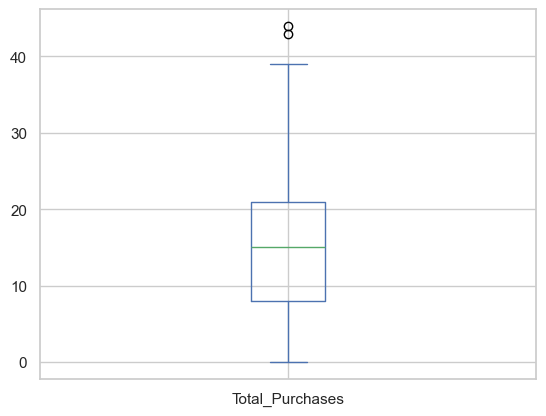

In [484]:
df["Total_Purchases"].plot(kind="box")
df["Total_Purchases"].skew()

In [485]:
purchase_category = ["NumDealsPurchases", "NumCatalogPurchases", "NumStorePurchases", "NumWebPurchases"]
purchase_count = df[purchase_category].sum()
purchase_count

NumDealsPurchases       5201
NumCatalogPurchases     5955
NumStorePurchases      12959
NumWebPurchases         9140
dtype: int64

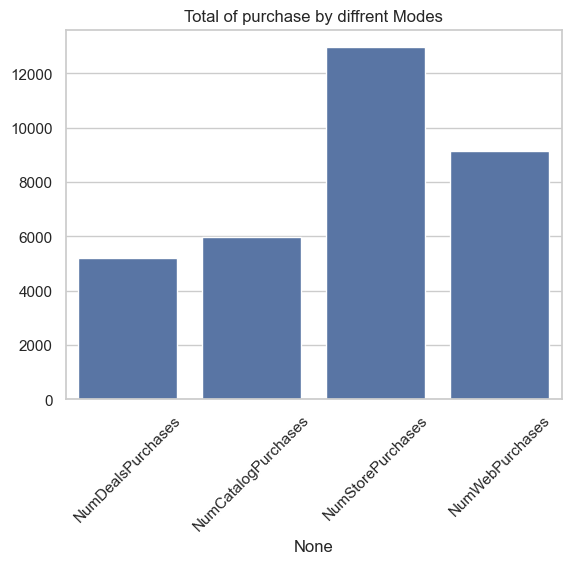

In [486]:
sns.set_theme(style="whitegrid")
sns.barplot(x=purchase_count.index, y=purchase_count.values)
plt.title("Total of purchase by diffrent Modes")
plt.xticks(rotation=45)
plt.show()

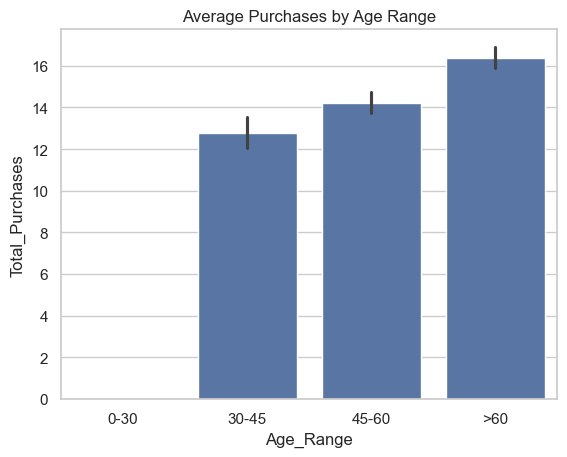

In [487]:

sns.barplot(data=df, x="Age_Range", y="Total_Purchases", estimator="mean")
plt.title("Average Purchases by Age Range")
plt.show()

In [488]:
df["NumStorePurchases"].sum()

np.int64(12959)

In [544]:
purchase_category = ["NumDealsPurchases", "NumCatalogPurchases", "NumStorePurchases", "NumWebPurchases"]
age_purchase_category_spend = df.groupby("Age_Range")[purchase_category].sum()
age_purchase_category_spend = age_purchase_category_spend.reset_index().melt(id_vars="Age_Range", 
                                                         var_name="Product_Mode", 
                                                         value_name="Number_Purchases")
age_purchase_category_spend

,Age_Range,Product_Mode,Number_Purchases
0,30-45,NumDealsPurchases,580
1,45-60,NumDealsPurchases,2441
2,>60,NumDealsPurchases,2180
3,30-45,NumCatalogPurchases,855
4,45-60,NumCatalogPurchases,2261
5,>60,NumCatalogPurchases,2839
6,30-45,NumStorePurchases,1822
7,45-60,NumStorePurchases,5397
8,>60,NumStorePurchases,5740
9,30-45,NumWebPurchases,1170


In [586]:
age_purchase = df.groupby("Age_Range")[purchase_category].sum()
total_by_age = age_purchase.sum(axis=1)
age_purchase_percent = age_purchase.div(total_by_age, axis=0) * 100
age_purchase_percent


percentage of purchases via different channels across age range:


,NumDealsPurchases,NumCatalogPurchases,NumStorePurchases,NumWebPurchases
Age_Range,,,,
30-45,13.101423,19.313305,41.156539,26.428733
45-60,17.464406,16.176576,38.613436,27.745582
>60,14.679146,19.116558,38.650596,27.553700


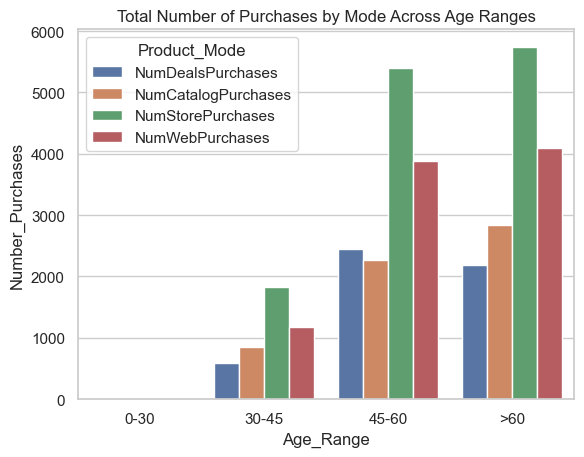

In [490]:
sns.barplot(data = age_purchase_category_spend, x="Age_Range", y="Number_Purchases", hue="Product_Mode")
plt.title("Total Number of Purchases by Mode Across Age Ranges")
plt.show()

In [491]:
children_spend_purchase = df.groupby("Total_Children")[["Total_Spending","Total_Purchases"]].sum()
print(children_spend_purchase)

                Total_Spending  Total_Purchases
Total_Children                                 
0                       703794            11186
1                       533094            16313
2                       103544             5137
3                        14554              619


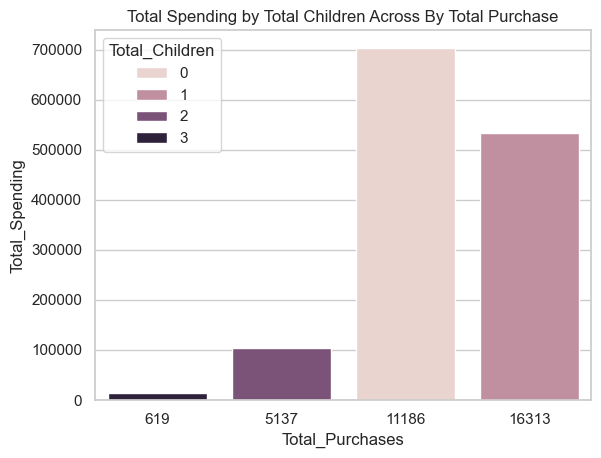

In [492]:
sns.barplot(data=children_spend_purchase, x="Total_Purchases", y="Total_Spending", hue="Total_Children")
plt.title("Total Spending by Total Children Across By Total Purchase")
plt.show()

In [587]:
children_purchase_behavior = df.groupby('Total_Children')[['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']].sum()
children_purchase_behavior

,NumWebPurchases,NumCatalogPurchases,NumStorePurchases
Total_Children,,,
0,2799,3030,4631
1,4828,2405,6303
2,1361,464,1815
3,152,56,210


In [593]:
total_per_group = children_purchase_behavior.sum(axis=1)
children_purchase_percent = children_purchase_behavior.div(total_per_group, axis=0) * 100
children_purchase_percent

,NumWebPurchases,NumCatalogPurchases,NumStorePurchases
Total_Children,,,
0,26.759082,28.967495,44.273423
1,35.667849,17.767435,46.564716
2,37.390110,12.747253,49.862637
3,36.363636,13.397129,50.239234


<Axes: xlabel='Total_Children'>

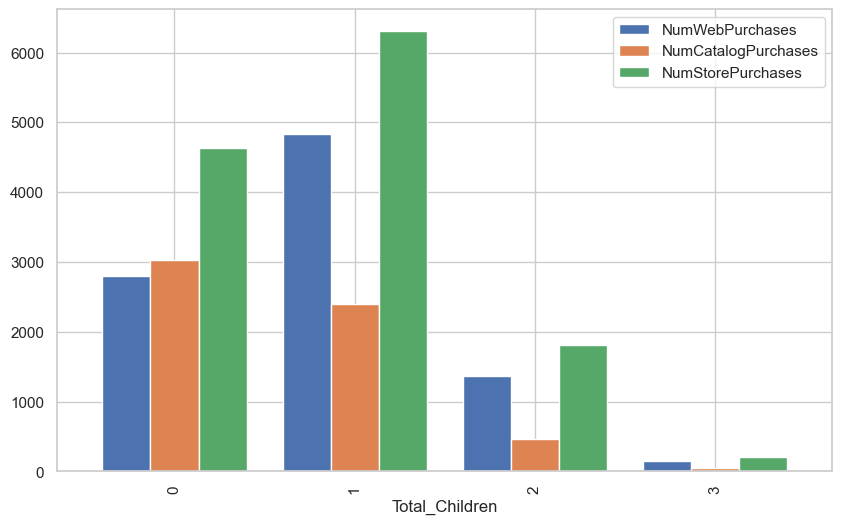

In [494]:
children_purchase_behavior.plot(kind='bar', figsize=(10, 6), width=0.8)

In [495]:
def transform_marital_status(value):
    if value == "YOLO" or value=="Absurd" or value == "Alone":
        return "Single"
    else:
        return value

Text(0.5, 1.0, 'Total Spending by Marital Status Across By Total Purchase')

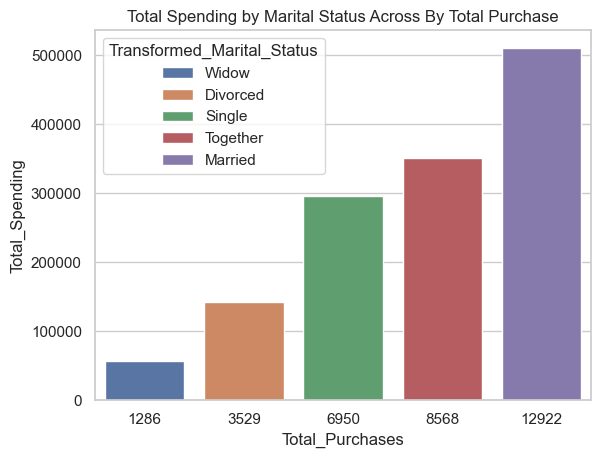

In [514]:
df["Transformed_Marital_Status"] = df["Marital_Status"].apply(transform_marital_status)
spend_purchase_martial_status = df.groupby("Transformed_Marital_Status")[["Total_Spending","Total_Purchases"]].sum()
sns.barplot(data=spend_purchase_martial_status, x="Total_Purchases", y="Total_Spending", hue="Transformed_Marital_Status")
plt.title("Total Spending by Marital Status Across By Total Purchase")

<Axes: xlabel='Total_Spending', ylabel='Total_Purchases'>

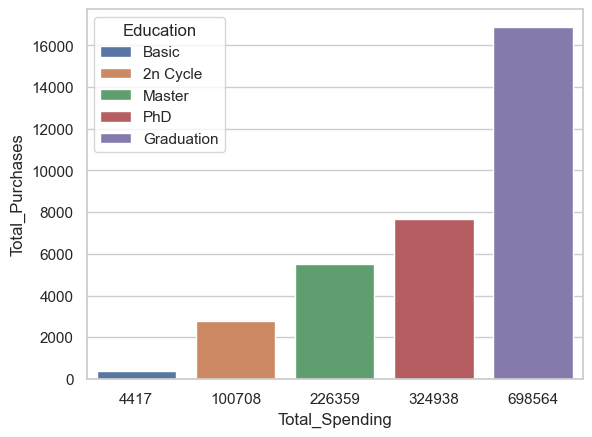

In [497]:
spend_purchase_education = df.groupby("Education")[["Total_Spending","Total_Purchases"]].sum()
sns.barplot(data=spend_purchase_education, x="Total_Spending", y="Total_Purchases", hue="Education")

### Purcahses and Spending of Country
1. Spain (SP) country has the most spending and purchases
2. SP has the most customer

In [498]:
country_total_purchases = df.groupby("Country")[["Total_Purchases", "Total_Spending"]].sum()
country_total_purchases

,Total_Purchases,Total_Spending
Country,,
AUS,2314,89763
CA,4101,168532
GER,1788,74913
IND,2093,79420
ME,59,3122
SA,5102,210987
SP,16037,660367
US,1761,67882


<Axes: xlabel='Total_Spending', ylabel='Total_Purchases'>

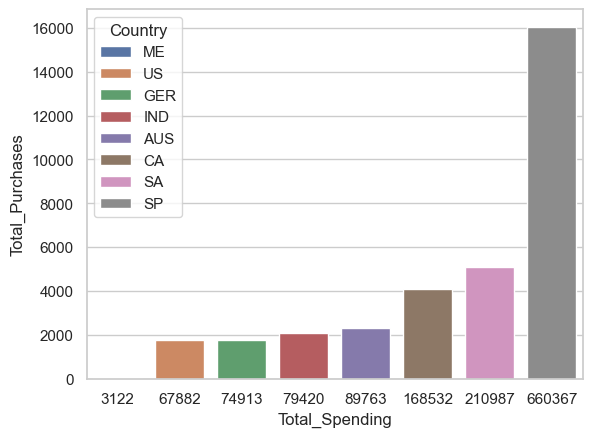

In [499]:
sns.barplot(data=country_total_purchases, x="Total_Spending", y="Total_Purchases", hue="Country")

In [501]:
country_total_customer = df.groupby("Country")["ID"].count().reset_index(name="Total_Customers")
country_total_customer
# or
# df["Country"].value_counts()

Country
SP     1094
SA      335
CA      268
AUS     160
IND     147
GER     120
US      109
ME        3
Name: count, dtype: int64

<Axes: xlabel='Country', ylabel='Total_Customers'>

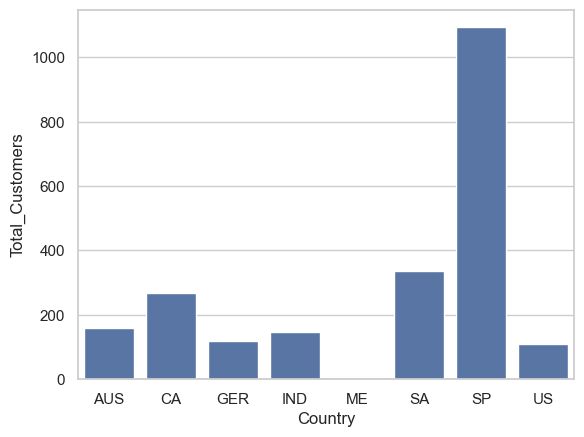

In [502]:
sns.barplot(data=country_total_customer, x="Country", y="Total_Customers")

### Customer Acceptance
1. Customer with age range 30-45 have accepted more
2. Spain has the accepted more

In [523]:
df["Total_AcceptedCmp"] = df["AcceptedCmp1"] + df["AcceptedCmp2"] + df["AcceptedCmp3"] + df["AcceptedCmp4"] + df["AcceptedCmp5"]
df["Total_AcceptedCmp"]

0       0
1       1
2       0
3       0
4       1
       ..
2235    0
2236    0
2237    0
2238    0
2239    2
Name: Total_AcceptedCmp, Length: 2236, dtype: int64

In [549]:
country_total_accepted_cmp = df.groupby("Country")[['AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1','AcceptedCmp2']].sum()
country_total_accepted_cmp

,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2
Country,,,,,
AUS,9,6,13,7,0
CA,18,24,21,18,6
GER,10,11,8,7,2
IND,13,11,6,7,2
ME,1,0,0,0,0
SA,21,20,21,20,4
SP,83,89,88,78,16
US,8,6,5,7,0


In [615]:
age_acceptance_data = pd.crosstab(df["AcceptedCmp5"], df["Age_Range"], normalize="columns" )*100

<Axes: ylabel='AcceptedCmp5'>

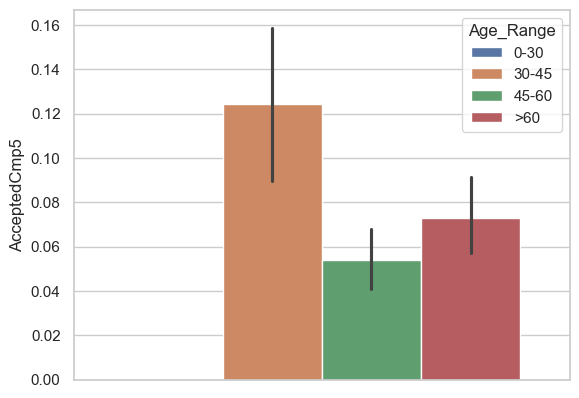

In [619]:
sns.barplot(data=df, y="AcceptedCmp5", hue="Age_Range")

<Axes: xlabel='Country', ylabel='AcceptedCmp5'>

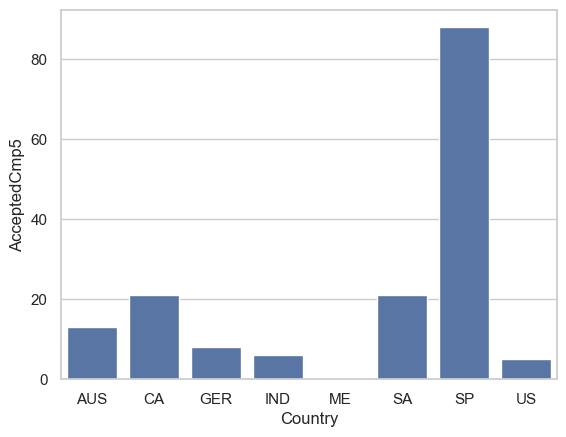

In [504]:
sns.barplot(data=country_total_accepted_cmp, x="Country", y="AcceptedCmp5")

### Complain
1. People who done graduation has more complaints

In [505]:
total_education_complain = df.groupby("Education")["Complain"].sum().reset_index(name="Complain")
total_education_complain

,Education,Complain
0,2n Cycle,3
1,Basic,0
2,Graduation,14
3,Master,2
4,PhD,1


In [506]:
pd.crosstab( df["Complain"],df["Education"], normalize="index")*100

Education,2n Cycle,Basic,Graduation,Master,PhD
Complain,,,,,
0,8.935018,2.436823,50.180505,16.606498,21.841155
1,15.000000,0.000000,70.000000,10.000000,5.000000


<Axes: xlabel='Education', ylabel='Complain'>

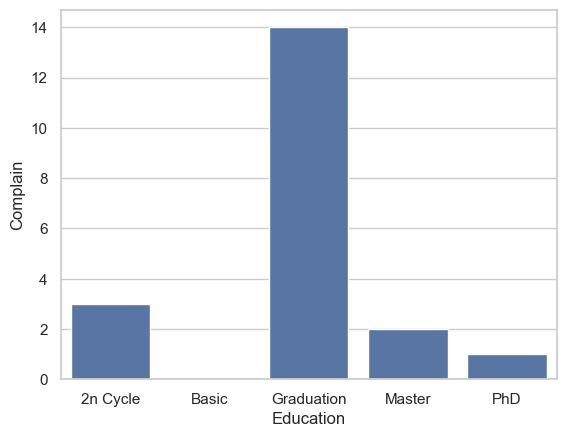

In [626]:
sns.barplot(data=total_education_complain, x="Education", y="Complain")

## Encoding

1. Education - Ordinal Encoding
2. Marital_Status - One hot encoding
3. Country - Frequency encoding

In [510]:
from sklearn.preprocessing import OrdinalEncoder
encoder = OrdinalEncoder(categories=[["Basic", "Graduation", "2n Cycle", "Master", "PhD"]])

# Fit and transform the column
df['Education_Encoded'] = encoder.fit_transform(df[['Education']]).astype("int")


In [521]:
df['Education_Encoded'].describe()

count    2236.000000
mean        2.047406
std         1.277402
min         0.000000
25%         1.000000
50%         1.000000
75%         3.000000
max         4.000000
Name: Education_Encoded, dtype: float64

In [515]:
df = pd.get_dummies(df, columns=['Transformed_Marital_Status'], drop_first=True, dtype=int)

In [516]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,Total_Purchases,Transformed_Marital_Status_Married,Transformed_Marital_Status_Single,Transformed_Marital_Status_Together,Transformed_Marital_Status_Widow,Education_Encoded,Transformed_Marital_Status_Married,Transformed_Marital_Status_Single,Transformed_Marital_Status_Together,Transformed_Marital_Status_Widow
0,1826,1970,Graduation,Divorced,84835.0,0,0,6/16/14,0,189,...,15,0,0,0,0,1,0,0,0,0
1,1,1961,Graduation,Single,57091.0,0,0,6/15/14,0,464,...,18,0,1,0,0,1,0,1,0,0
2,10476,1958,Graduation,Married,67267.0,0,1,5/13/14,0,134,...,11,1,0,0,0,1,1,0,0,0
3,1386,1967,Graduation,Together,32474.0,1,1,5/11/14,0,10,...,4,0,0,1,0,1,0,0,1,0
4,5371,1989,Graduation,Single,21474.0,1,0,4/8/14,0,6,...,8,0,1,0,0,1,0,1,0,0


In [517]:
country_counts = df['Country'].value_counts()
df['Country_Encoded'] = df['Country'].apply(lambda x: country_counts[x])
country_counts

Country
SP     1094
SA      335
CA      268
AUS     160
IND     147
GER     120
US      109
ME        3
Name: count, dtype: int64

In [518]:
df.Country_Encoded

0       1094
1        268
2        109
3        160
4       1094
        ... 
2235     109
2236    1094
2237    1094
2238     147
2239     268
Name: Country_Encoded, Length: 2236, dtype: int64

### Heat Maps 

In [527]:

corr_data = df[["Scaled_Income", "Total_Children", "Education_Encoded", "Total_Purchases", "Total_Spending", "Response", "Country_Encoded", "Total_AcceptedCmp","Recency"]].corr(numeric_only=True)

<Axes: >

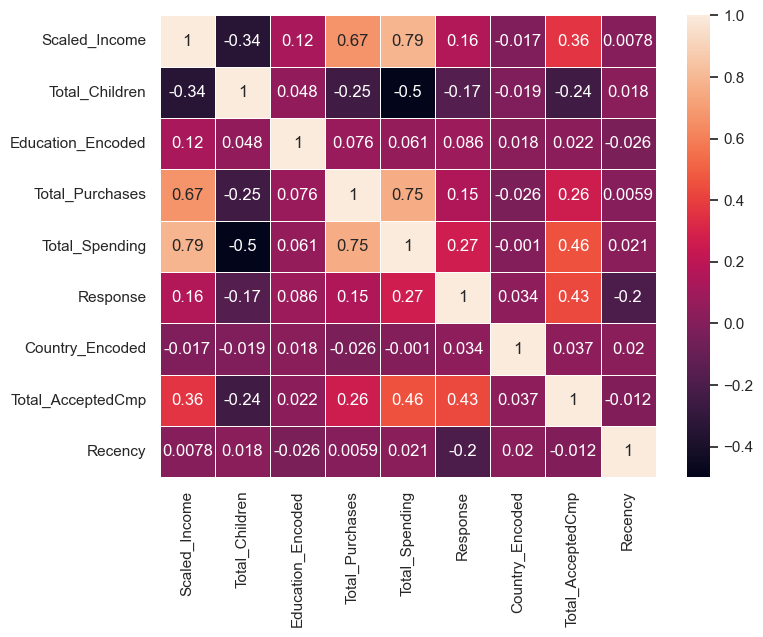

In [536]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_data, annot=True, linewidth=.5, vmin=-0.5, vmax=1, ax=ax)

<Axes: >

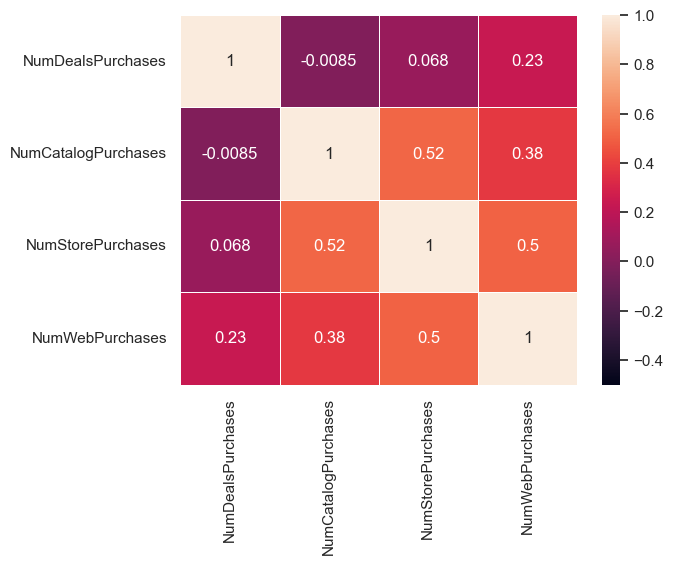

In [613]:
channel_data = df[["NumDealsPurchases", "NumCatalogPurchases", "NumStorePurchases", "NumWebPurchases"]].corr(numeric_only=True)
sns.heatmap(channel_data, annot=True, linewidth=.5, vmin=-0.5, vmax=1)